In [2]:
import os

os.chdir(r"D:\DATA SCIENCE Project 2026")

print(os.getcwd())
print(os.listdir())

D:\DATA SCIENCE Project 2026
['phishing_site_urls.csv']


In [4]:
import os

os.chdir(r"D:\DATA SCIENCE Project 2026")

print(os.listdir())

['phishing_site_urls.csv']


In [5]:
import pandas as pd

df = pd.read_csv("phishing_site_urls.csv")

df.head()

,URL,Label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad
3,mail.printakid.com/www.online.americanexpress....,bad
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad


In [6]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nLabel Distribution:")
print(df['Label'].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (549346, 2)

Column Names:
Index(['URL', 'Label'], dtype='object')

Label Distribution:
Label
good    392924
bad     156422
Name: count, dtype: int64

Missing Values:
URL      0
Label    0
dtype: int64


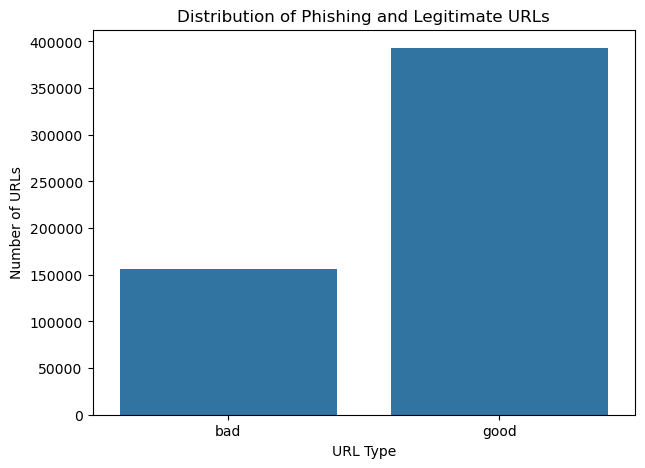

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Label')

plt.title("Distribution of Phishing and Legitimate URLs")
plt.xlabel("URL Type")
plt.ylabel("Number of URLs")

plt.show()

In [8]:
df['Label'] = df['Label'].map({
    'good': 0,
    'bad': 1
})

df.head()

,URL,Label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,1
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,1
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,1
3,mail.printakid.com/www.online.americanexpress....,1
4,thewhiskeydregs.com/wp-content/themes/widescre...,1


In [ ]:
from urllib.parse import urlparse

def extract_features(url):
    features = {}

    features['url_length'] = len(url)
    features['dot_count'] = url.count('.')
    features['hyphen_count'] = url.count('-')
    features['at_count'] = url.count('@')
    features['digit_count'] = sum(c.isdigit() for c in url)
    features['https'] = int(url.startswith('https://'))
    features['slash_count'] = url.count('/')

    return features

features_df = df['URL'].apply(extract_features).apply(pd.Series)

features_df.head()

In [ ]:
print(features_df.shape)

In [11]:
import numpy as np

urls = df['URL'].astype(str)

features_df = pd.DataFrame({
    'url_length': urls.str.len(),
    'dot_count': urls.str.count(r'\.'),
    'hyphen_count': urls.str.count('-'),
    'at_count': urls.str.count('@'),
    'digit_count': urls.str.count(r'\d'),
    'https': urls.str.startswith('https://').astype(int),
    'slash_count': urls.str.count('/')
})

features_df.head()

,url_length,dot_count,hyphen_count,at_count,digit_count,https,slash_count
0,225,6,4,0,58,0,10
1,81,5,2,0,1,0,4
2,177,7,1,0,47,0,11
3,60,6,0,0,0,0,2
4,116,1,1,0,21,0,10


In [12]:
from sklearn.model_selection import train_test_split

X = features_df
y = df['Label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (439476, 7)
Testing data: (109870, 7)


In [13]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [14]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 84.40338581960499 %

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.94      0.90     78585
           1       0.80      0.60      0.69     31285

    accuracy                           0.84    109870
   macro avg       0.83      0.77      0.79    109870
weighted avg       0.84      0.84      0.84    109870


Confusion Matrix:
[[73864  4721]
 [12415 18870]]


In [15]:
model_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

model_balanced.fit(X_train, y_train)

y_pred_balanced = model_balanced.predict(X_test)

print(classification_report(y_test, y_pred_balanced))

              precision    recall  f1-score   support

           0       0.89      0.84      0.86     78585
           1       0.65      0.74      0.69     31285

    accuracy                           0.81    109870
   macro avg       0.77      0.79      0.78    109870
weighted avg       0.82      0.81      0.82    109870



In [16]:
import joblib

joblib.dump(model_balanced, 'phishing_model.pkl')

joblib.dump(
    list(features_df.columns),
    'feature_names.pkl'
)

print("Model saved successfully!")

Model saved successfully!


In [17]:
def check_url(url):
    features = pd.DataFrame([{
        'url_length': len(url),
        'dot_count': url.count('.'),
        'hyphen_count': url.count('-'),
        'at_count': url.count('@'),
        'digit_count': sum(c.isdigit() for c in url),
        'https': int(url.startswith('https://')),
        'slash_count': url.count('/')
    }])

    prediction = model_balanced.predict(features)[0]
    probability = model_balanced.predict_proba(features)[0][1]

    if prediction == 1:
        print("WARNING: Potentially Phishing URL")
    else:
        print("Likely Legitimate URL")

    print("Phishing Risk:", round(probability * 100, 2), "%")

In [18]:
check_url("http://secure-login-paypal.example.com/verify")

Likely Legitimate URL
Phishing Risk: 39.23 %


In [19]:
import re
from urllib.parse import urlparse

def extract_advanced_features(url):
    url = str(url)
    parsed = urlparse(url if '://' in url else '//' + url)

    suspicious_words = [
        'login', 'verify', 'secure', 'account',
        'update', 'banking', 'password', 'signin'
    ]

    return {
        'url_length': len(url),
        'dot_count': url.count('.'),
        'hyphen_count': url.count('-'),
        'at_count': url.count('@'),
        'digit_count': sum(c.isdigit() for c in url),
        'https': int(url.startswith('https://')),
        'slash_count': url.count('/'),
        'suspicious_word_count': sum(
            word in url.lower() for word in suspicious_words
        ),
        'ip_address': int(bool(re.match(
            r'^(\d{1,3}\.){3}\d{1,3}$', parsed.hostname or ''
        ))),
        'subdomain_count': max(0, len((parsed.hostname or '').split('.')) - 2),
        'query_count': url.count('?'),
        'shortening_service': int(any(
            domain in (parsed.hostname or '').lower()
            for domain in ['bit.ly', 'tinyurl.com', 't.co', 'goo.gl']
        ))
    }

print(extract_advanced_features(
    "http://secure-login-paypal.example.com/verify"
))

{'url_length': 45, 'dot_count': 2, 'hyphen_count': 2, 'at_count': 0, 'digit_count': 0, 'https': 0, 'slash_count': 3, 'suspicious_word_count': 3, 'ip_address': 0, 'subdomain_count': 1, 'query_count': 0, 'shortening_service': 0}


In [20]:
urls = df['URL'].astype(str)
lower_urls = urls.str.lower()

# Extract domain name
hosts = (lower_urls
         .str.replace(r'^[a-zA-Z][a-zA-Z0-9+.-]*://', '', regex=True)
         .str.split(r'[/?:#]', n=1).str[0]
         .str.split('@').str[-1])

# Suspicious words
words = ['login', 'verify', 'secure', 'account',
         'update', 'banking', 'password', 'signin']

advanced_features = features_df.copy()

advanced_features['suspicious_word_count'] = sum(
    lower_urls.str.count(word) for word in words
)

advanced_features['ip_address'] = hosts.str.match(
    r'^(\d{1,3}\.){3}\d{1,3}$'
).astype(int)

advanced_features['subdomain_count'] = (
    hosts.str.count(r'\.') - 1
).clip(lower=0)

advanced_features['query_count'] = urls.str.count(r'\?')

advanced_features['shortening_service'] = hosts.str.contains(
    r'(^|\.)(bit\.ly|tinyurl\.com|t\.co|goo\.gl)$',
    regex=True
).astype(int)

print("Advanced dataset shape:", advanced_features.shape)
advanced_features.head()

C:\Users\Asus\AppData\Local\Temp\ipykernel_17644\2159751037.py:30: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  advanced_features['shortening_service'] = hosts.str.contains(


Advanced dataset shape: (549346, 12)


,url_length,dot_count,hyphen_count,at_count,digit_count,https,slash_count,suspicious_word_count,ip_address,subdomain_count,query_count,shortening_service
0,225,6,4,0,58,0,10,3,0,0,1,0
1,81,5,2,0,1,0,4,0,0,1,0,0
2,177,7,1,0,47,0,11,3,0,0,0,0
3,60,6,0,0,0,0,2,0,0,1,0,0
4,116,1,1,0,21,0,10,0,0,0,1,0


In [21]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

model = joblib.load("phishing_model.pkl")

st.set_page_config(page_title="PHISHGUARD", page_icon="🛡️")

st.title("🛡️ PHISHGUARD")
st.subheader("Phishing URL Risk Classification")

st.write("Enter a website URL to check its phishing risk.")

url = st.text_input("Enter Website URL")

if st.button("Check URL"):
    if url.strip():

        features = pd.DataFrame([{
            'url_length': len(url),
            'dot_count': url.count('.'),
            'hyphen_count': url.count('-'),
            'at_count': url.count('@'),
            'digit_count': sum(c.isdigit() for c in url),
            'https': int(url.startswith('https://')),
            'slash_count': url.count('/')
        }])

        prediction = model.predict(features)[0]
        risk = model.predict_proba(features)[0][1] * 100

        if prediction == 1:
            st.error("Potentially Phishing Website!")
        else:
            st.success("Likely Legitimate Website")

        st.metric("Estimated Phishing Risk", f"{risk:.2f}%")
        st.caption("This is an ML-based estimate, not a guarantee of website safety.")

    else:
        st.warning("Please enter a URL.")

Writing app.py
